In [4]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Datasets
df_train = pd.read_csv(r"/Users/lennartheld/DSP/data/train.csv")
df_test = pd.read_csv(r"/Users/lennartheld/DSP/data/test.csv")

# Grouping training datasets into numerical and categorical datasets
df_train_num = df_train[['PassengerId', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']]
df_train_cat = df_train[['Survived', 'Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']]

In [5]:

# General overview over data
# df_train.info()
# df_train.describe()

# Plot histogram for each column of numerical data
'''
for i in df_train_num.columns:
    plt.hist(df_train_num[i], bins=16, edgecolor= 'black')
    plt.title(i)
    plt.show()
'''

# Filter & plot boxplots for each column of numerical and continuous data
'''
plt.boxplot(df_train_num['Age'].dropna())
plt.title('Age')
plt.show()
'''

# Plot correlation between numerical data values
'''
print(df_train_num.corr())
sns.heatmap(df_train_num.corr(), annot=True, center=0)
'''

# Pivot table to show complex filtered data 
'''
df_train.pivot_table(index='Survived', values = ['Age', 'SibSp', 'Parch', 'Fare'], aggfunc = ['mean', 'median', 'std', 'min', 'max']) 
'''

# Histogram for categorical data (cabin and ticket graphs are not very useful due to the high number of unique values)
'''
for i in df_train_cat.columns:
    sns.barplot(x=df_train_cat[i].value_counts().index, y=df_train_cat[i].value_counts()) 
    plt.show()
'''

# Further pivot tables to show complex filtered data
display(df_train.pivot_table(index='Survived', columns='Pclass', values='Fare', aggfunc='mean').round(2))
display(df_train.pivot_table(index='Survived', columns='Sex', values='Fare', aggfunc='mean').round(2))
display(df_train.pivot_table(index='Survived', columns='Embarked', values='Fare', aggfunc='mean').round(2))


Pclass,1,2,3
Survived,,,
0,64.68,19.41,13.67
1,95.61,22.06,13.69


Sex,female,male
Survived,,
0,23.02,21.96
1,51.94,40.82


Embarked,C,Q,S
Survived,,,
0,35.44,13.34,20.74
1,79.72,13.18,39.55


In [ ]:
# Check for passenger survival rate based on multiple cabins were assigned to a passenger
df_train_cat['Multiple_Cabins'] = df_train_cat['Cabin'].apply(lambda x: 0 if pd.isna(x) else len(x.split(' ')))
df_train_cat['Multiple_Cabins'].value_counts()

# Check if different ticket types had impact on survival rate
df_train_cat.pivot_table(index='Survived', columns='Multiple_Cabins', values='Ticket', aggfunc='count').round(0)

# Create category for ticket types based on the first letter of the ticket number
df_train_cat['Cabin_Letter'] = df_train_cat['Cabin'].apply(lambda x: str(x)[0] if pd.isna(x) == False else 'n')

# Comparison of survival rate by cabin
df_train_cat.pivot_table(index='Survived', columns='Cabin_Letter', values= 'Name', aggfunc='count').round(0)

# Preprocessing of Numerical -and Non Numerical Tickets
df_train_cat['Numerical_Ticket'] = df_train_cat['Ticket'].apply(lambda x: 1 if str(x).isnumeric() else 0) 
df_train_cat['Non_Numerical_Ticket'] = df_train_cat['Ticket'].apply(lambda x: ''.join(x.split(' ')[:-1]).replace(".","").replace("/","").lower() if len (x.split(' ')[:-1]) >0 else 0)
# display(df_train_cat[['Numerical_Ticket', 'Non_Numerical_Ticket']])

pd.set_option('display.max_rows', None)
df_train_cat['Non_Numerical_Ticket'].value_counts()

# Extraction of titles
df_train_cat['Title'] = df_train_cat['Name'].apply(lambda x: x.split(',')[1].split('.')[0].strip())  

886    0.0
887    1.0
888    0.0
889    1.0
890    0.0
Name: Survived, dtype: float64

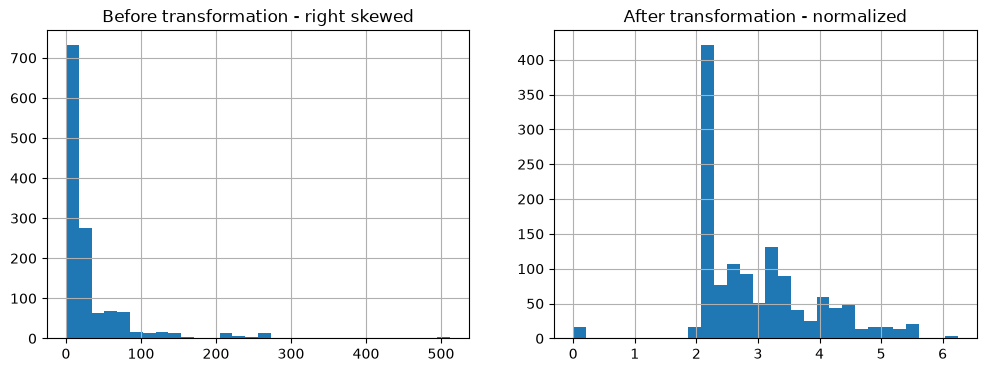

In [ ]:
# Data preprocessing (generate dataset with relevant columns, preprocessing steps)
# Relevant features - Pclass, Sex, Age, SibSp, ParCh, Fare, Embarked, Cabin_Letter, Multiple_Cabins, Numerical_Ticket, Title

# auxilliary columns for train- and test dataset
df_train['Aux_Col'] = 1
df_test['Aux_Col']= 0

# concat train and test dataframes
all_df = pd.concat([df_train, df_test], ignore_index=True)

# add features to all_df
all_df['Cabin_Letter'] = all_df['Cabin'].apply(lambda x: str(x)[0] if pd.isna(x) == False else 'n')
all_df['Multiple_Cabins'] = all_df['Cabin'].apply(lambda x: 0 if pd.isna(x) else len(x.split(' ')))
all_df['Numerical_Ticket'] = all_df['Ticket'].apply(lambda x: 1 if str(x).isnumeric() else 0)
all_df['Title'] = all_df['Name'].apply(lambda x: x.split(',')[1].split('.')[0].strip())

# Interpolate / fill missing values of dataframe with median values of each column
all_df['Age'] = all_df['Age'].fillna(all_df['Age'].median())
all_df['Fare'] = all_df['Fare'].fillna(all_df['Fare'].median())
all_df = all_df.dropna(subset=['Embarked'])
# all_df.isna().sum()

# Log-Transformation ln(x+1) to scale the values of 'Fare' correctly (right skewed distribution of values)
all_df['Norm_Fare'] = np.log(all_df['Fare'] +1)

# Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
all_df['Fare'].hist(bins=30, ax=axes[0])
axes[0].set_title('Before transformation - right skewed')
all_df['Norm_Fare'].hist(bins=30, ax=axes[1])
axes[1].set_title('After transformation - normalized')

# One-Hot Encoding for categorical variables 
all_df['Pclass'] = all_df['Pclass'].astype(str)
all_dummies = pd.get_dummies(all_df[['Pclass', 'Sex', 'Embarked', 'Aux_Col', 'Age', 'SibSp', 'Parch', 'Norm_Fare', 'Cabin_Letter', 'Multiple_Cabins', 'Numerical_Ticket', 'Title']], dtype=int) # create df with one-hot encoded and non-encoded columns

# Split dataframe into train and test datasets
x_train = all_dummies[all_dummies['Aux_Col'] == 1].drop(columns=['Aux_Col'])
x_test = all_dummies[all_dummies['Aux_Col'] == 0].drop(columns=['Aux_Col'])

y_train = all_df[all_df['Aux_Col']==1]['Survived']
# y_train.shape

